# Complete IMC Data Analysis Workflow

Raw imaging mass cytometry (IMC) data from the chondrosarcoma tissue microarray are processed into analysis-ready single-cell tables in eight stages:

1. The raw single-channel OME-TIFF files of each region of interest (ROI) are inspected.
2. The Steinbock `panel.csv` is generated from the channel filenames present in `data/raw/`.
3. Marker availability is recorded for every ROI.
4. The channels of each ROI are hot-pixel filtered and stacked into one multi-channel TIFF image.
5. Cells are segmented with Cellpose from a nuclear and a membrane/cell-boundary composite.
6. Mean marker intensities are measured for every cell.
7. Cell morphology and centroid coordinates are measured.
8. Spatial neighbour graphs are constructed, and single-cell tables and graph objects are exported.

Panel contents, ROI counts and all summaries are derived from the files present in `data/raw/` and are not fixed in the code. The workflow is therefore applicable to single ROIs, test subsets and complete CH or CHS batches.

### Changes relative to the predecessor workflow

The processing steps follow `260812_imcAnalysis_cellpose_AllImages/notebooks/01_Complete IMC Data Analysis Workflow.ipynb`. The items of the pipeline review (`docs/review/20261004 IMC_Pipeline_Review_for_Rashid.md`) listed below are implemented; item numbers refer to that document.

| Item | Step | Change |
|---|---|---|
| 2.2 | 2, 4 | Segmentation marker set: nuclear DNA1, DNA2, SOX9; membrane S100, CD68, aSMA, CD31, CD3, CD66b (CD20, CD138 and CD163 removed). Fixed per-channel composite scaling is implemented and benchmarked |
| 2.3 | 2 | `analysis` column added to `panel.csv`: 0 for the six technical channels, 1 otherwise; `keep` unchanged |
| 2.6 | 2, 4 | Documented segmentation channels agree with the code |
| 1.1 | 3 | Steinbock hot-pixel filter (threshold 50 counts) applied to every channel before stacking |
| 1.3 | 3 | Output images named after the TMA core map (ROI032–041 carry their TMA position); raw folders are not renamed |
| 1.4 | 3 | Minimum image-size filter disabled by default (27 ROIs are not 1000 × 1000 px) |
| 4.4 | 4 | Cellpose model, package versions and host are logged; existing masks are skipped, and failures of individual ROIs are logged without interrupting the run |

All outputs are regenerated with these changes; no output of the predecessor workflow is reused.

## Step 0: Workflow Directory Resolution

The workflow root is resolved before any processing. It is located from the workflow directory itself, from a subfolder such as `notebooks/`, or from a parent directory containing the workflow folder. When none of these applies, the root is read from the environment variable `IMC_WORKFLOW_DIR`.

A directory is recognised as the workflow root when it contains:

```text
data/raw/
scripts/
notebooks/
```

Output folders such as `logs/`, `results/`, `figures/`, `data/img/` and `data/masks/` are created inside the resolved root when the corresponding steps are run.

`data/raw` is a symbolic link to the raw ROI folders of the predecessor project. The raw data are accessed read-only, and no step writes into `data/raw`.

## Output Numbering Rule

Steinbock requires fixed working names for its files and folders, including `data/panel.csv`, `data/images.csv`, `data/img/`, `data/masks/` and `data/cells.csv`. These names are retained in `data/`. In addition, a copy of each output is written to `results/` with a two-digit prefix that reflects the order in which the outputs are generated (e.g. `01_panel.csv`, `02_images.csv`).

In [1]:
from pathlib import Path
import csv
import os
import re
import subprocess
import sys


def _child_dirs(path: Path) -> list[Path]:
    try:
        return [child for child in path.iterdir() if child.is_dir()]
    except OSError:
        return []


def _is_workflow_dir(candidate: Path) -> bool:
    return (
        (candidate / 'data' / 'raw').exists()
        and (candidate / 'scripts').is_dir()
        and (candidate / 'notebooks').is_dir()
    )


def find_workflow_dir(start: Path) -> Path:
    start = start.resolve()

    ancestry_candidates = [start, *start.parents]
    for candidate in ancestry_candidates:
        if _is_workflow_dir(candidate):
            return candidate

    sibling_candidates = []
    for parent in [start, *start.parents[:3]]:
        sibling_candidates.extend(_child_dirs(parent))

    seen = {candidate.resolve() for candidate in ancestry_candidates}
    for candidate in sibling_candidates:
        candidate = candidate.resolve()
        if candidate in seen:
            continue
        if _is_workflow_dir(candidate):
            return candidate
        seen.add(candidate)

    env_dir = os.environ.get('IMC_WORKFLOW_DIR')
    if env_dir:
        candidate = Path(env_dir).expanduser().resolve()
        if _is_workflow_dir(candidate):
            print(f'Using IMC_WORKFLOW_DIR fallback: {candidate}')
            return candidate

    raise FileNotFoundError(
        'Could not locate the IMC workflow directory from the current notebook location. '
        'If needed, set IMC_WORKFLOW_DIR explicitly to the workflow root.'
    )


WORKFLOW_DIR = find_workflow_dir(Path.cwd())
DATA_DIR = WORKFLOW_DIR / 'data'
RAW_DIR = DATA_DIR / 'raw'
# RAW_DIR = Path("/Volumes/ricerca/Unita_Imaging/Shared/Hyperion/Projects/Cananzi/20260116_TMA/IMC_data/CHS/Tiffs")
SCRIPTS_DIR = WORKFLOW_DIR / 'scripts'
LOGS_DIR = WORKFLOW_DIR / 'logs'

for path in [DATA_DIR, RAW_DIR, SCRIPTS_DIR, LOGS_DIR]:
    print(f'{path.name}: {path.exists()} -> {path}')


data: True -> /Users/rashid/1_IMC_Analysis/11_Vincenzo/261007_imcAnalysis_cellpose_Refined/data
raw: True -> /Users/rashid/1_IMC_Analysis/11_Vincenzo/261007_imcAnalysis_cellpose_Refined/data/raw
scripts: True -> /Users/rashid/1_IMC_Analysis/11_Vincenzo/261007_imcAnalysis_cellpose_Refined/scripts
logs: True -> /Users/rashid/1_IMC_Analysis/11_Vincenzo/261007_imcAnalysis_cellpose_Refined/logs


## Step 1: Inspect Raw IMC Inputs

Input files are read from `data/raw/`, which points to the in-house data folder. The following structure is expected:

- one folder per ROI, e.g. `ROI073_A14/`;
- one single-channel `.ome.tiff` file per marker within each ROI folder;
- filenames of the form `<channel>_<marker>.ome.tiff`, e.g. `142Nd_CD138.ome.tiff`.

The presence of the ROI folders and marker-channel files is verified before processing.

In [2]:
roi_dirs = sorted(path for path in RAW_DIR.iterdir() if path.is_dir() and any(path.glob('*.ome.tiff')))

print(f'ROI folders: {len(roi_dirs)}')
for roi_dir in roi_dirs:
    channel_files = sorted(roi_dir.glob('*.ome.tiff'))
    summary_files = sorted(roi_dir.glob('*_summary.txt'))
    print(f'  {roi_dir.name}: {len(channel_files)} channel TIFFs, {len(summary_files)} summary files')
    for path in channel_files[:5]:
        print('    ', path.name)
    if len(channel_files) > 5:
        print(f'     ... {len(channel_files) - 5} more')

all_channel_sets = {roi_dir.name: {path.name for path in roi_dir.glob('*.ome.tiff')} for roi_dir in roi_dirs}
if roi_dirs:
    reference_name = roi_dirs[0].name
    reference = all_channel_sets[reference_name]
    mismatched = [name for name, names in all_channel_sets.items() if names != reference]
    print(f'Consistent marker-channel file set across ROI folders: {not mismatched}')
    if mismatched:
        print('Mismatching ROI folders:', mismatched)


ROI folders: 136
  ROI001_E10: 43 channel TIFFs, 1 summary files
     115In_CD20.ome.tiff
     127I_127I.ome.tiff
     131Xe_131Xe.ome.tiff
     134Xe_134Xe.ome.tiff
     138Ba_138Ba.ome.tiff
     ... 38 more
  ROI002_F12: 43 channel TIFFs, 1 summary files
     115In_CD20.ome.tiff
     127I_127I.ome.tiff
     131Xe_131Xe.ome.tiff
     134Xe_134Xe.ome.tiff
     138Ba_138Ba.ome.tiff
     ... 38 more
  ROI003_C4: 43 channel TIFFs, 1 summary files
     115In_CD20.ome.tiff
     127I_127I.ome.tiff
     131Xe_131Xe.ome.tiff
     134Xe_134Xe.ome.tiff
     138Ba_138Ba.ome.tiff
     ... 38 more
  ROI004_I7: 43 channel TIFFs, 1 summary files
     115In_CD20.ome.tiff
     127I_127I.ome.tiff
     131Xe_131Xe.ome.tiff
     134Xe_134Xe.ome.tiff
     138Ba_138Ba.ome.tiff
     ... 38 more
  ROI005_J4: 43 channel TIFFs, 1 summary files
     115In_CD20.ome.tiff
     127I_127I.ome.tiff
     131Xe_131Xe.ome.tiff
     134Xe_134Xe.ome.tiff
     138Ba_138Ba.ome.tiff
     ... 38 more
  ROI006_B12: 43 channel T

### Preview: All Marker Channels for One ROI

All raw marker channels of a single ROI are displayed for visual inspection, each labelled by marker name rather than by isotope code or channel index. The images are read directly from the single-channel OME-TIFF files in `data/raw/<ROI>/` and are therefore independent of the panel and stacking steps.

For display only, each channel is contrast-stretched independently between its 1st and 99.5th percentiles; no file on disk is modified. The preview is not a processing step.

The ROI shown is set by `PREVIEW_ROI` in the cell below.

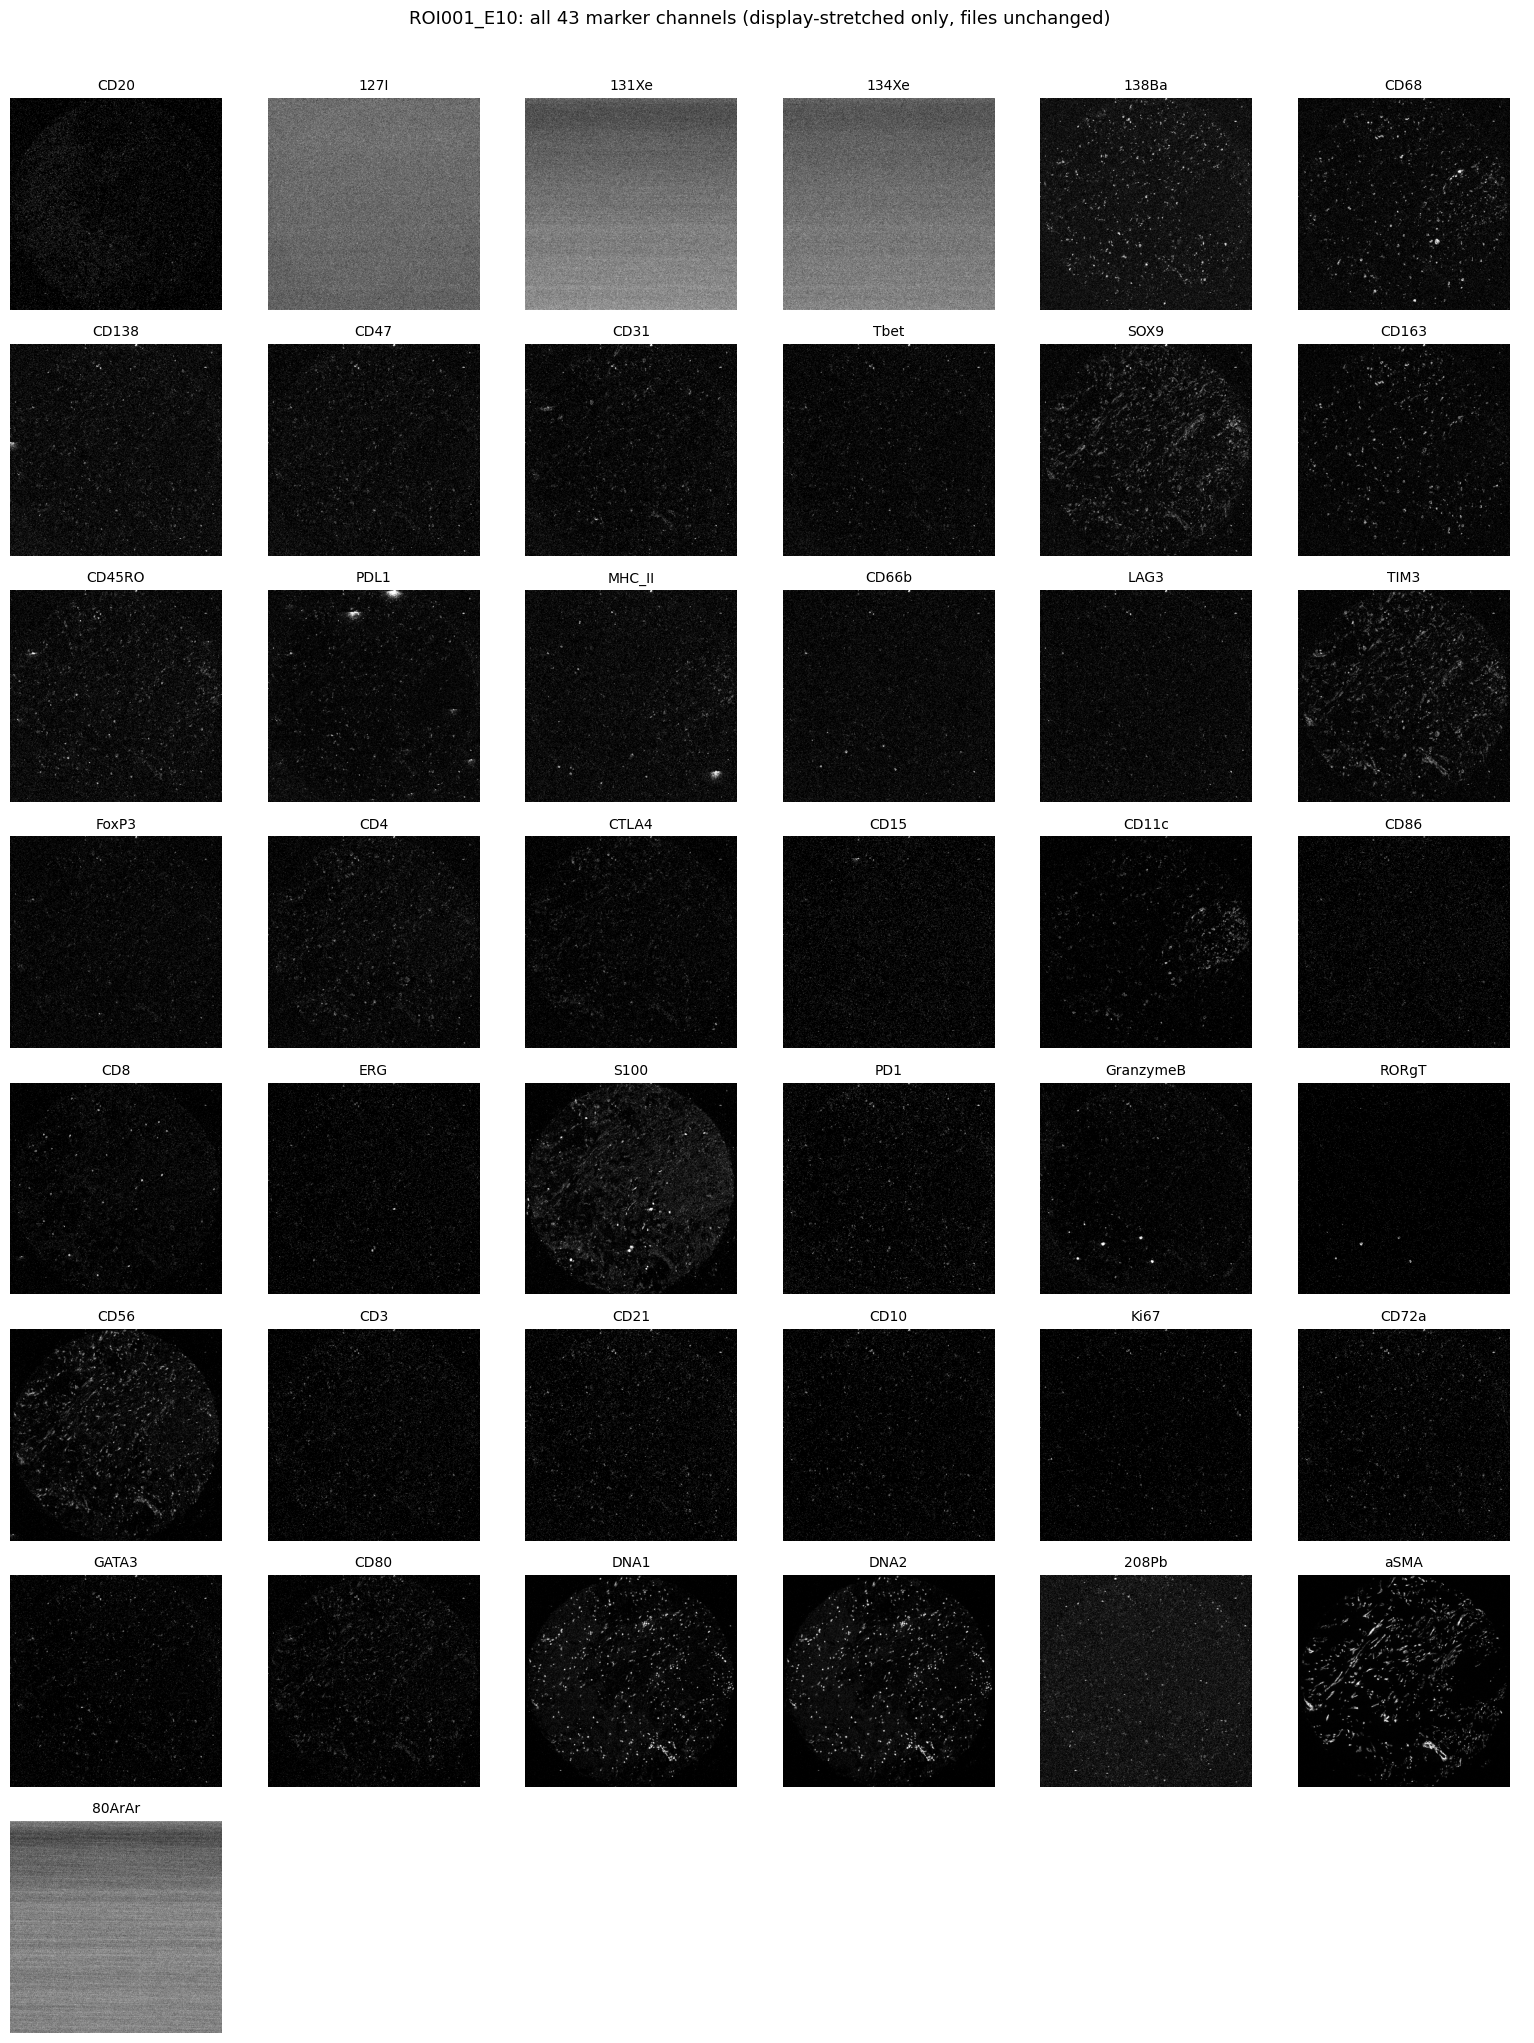

ROI previewed: ROI001_E10
Channels shown: 43
Channel -> marker mapping:
  115In_CD20.ome.tiff            -> CD20
  127I_127I.ome.tiff             -> 127I
  131Xe_131Xe.ome.tiff           -> 131Xe
  134Xe_134Xe.ome.tiff           -> 134Xe
  138Ba_138Ba.ome.tiff           -> 138Ba
  141Pr_CD68.ome.tiff            -> CD68
  142Nd_CD138.ome.tiff           -> CD138
  143Nd_CD47.ome.tiff            -> CD47
  144Nd_CD31.ome.tiff            -> CD31
  145Nd_Tbet.ome.tiff            -> Tbet
  146Nd_SOX9.ome.tiff            -> SOX9
  148Nd_CD163.ome.tiff           -> CD163
  149Sm_CD45RO.ome.tiff          -> CD45RO
  150Nd_PDL1.ome.tiff            -> PDL1
  151Eu_MHC_II.ome.tiff          -> MHC_II
  152Sm_CD66b.ome.tiff           -> CD66b
  153Eu_LAG3.ome.tiff            -> LAG3
  154Sm_TIM3.ome.tiff            -> TIM3
  155Gd_FoxP3.ome.tiff           -> FoxP3
  156Gd_CD4.ome.tiff             -> CD4
  158Gd_CTLA4.ome.tiff           -> CTLA4
  159Tb_CD15.ome.tiff            -> CD15
  160Gd_CD11c.o

In [3]:
import numpy as np
import tifffile
import matplotlib.pyplot as plt

# Change this to preview a different ROI.
PREVIEW_ROI = 'ROI001_E10' if (RAW_DIR / 'ROI001_E10').exists() else roi_dirs[0].name

roi_dir = RAW_DIR / PREVIEW_ROI
channel_files = sorted(roi_dir.glob('*.ome.tiff'))


def marker_name(path):
    # filenames follow <channel>_<marker>.ome.tiff, e.g. 142Nd_CD138.ome.tiff
    stem = path.name[: -len('.ome.tiff')]
    channel, _, marker = stem.partition('_')
    return marker or channel


def display_stretch(array):
    # Display-only contrast stretch (1st-99.5th percentile). Nothing is
    # written back to data/raw/ -- this only affects what is plotted here.
    array = array.astype(np.float32)
    low, high = np.percentile(array, [1, 99.5])
    if high <= low:
        return np.zeros_like(array)
    return np.clip((array - low) / (high - low), 0.0, 1.0)


channels = [(marker_name(path), path) for path in channel_files]
n_channels = len(channels)
ncols = 6
nrows = -(-n_channels // ncols)  # ceil division

fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 2.6, nrows * 2.6))
axes = np.atleast_2d(axes)
for ax in axes.flat:
    ax.axis('off')

for ax, (marker, path) in zip(axes.flat, channels):
    image = tifffile.imread(path)
    ax.imshow(display_stretch(image), cmap='gray')
    ax.set_title(marker, fontsize=10)

fig.suptitle(f'{PREVIEW_ROI}: all {n_channels} marker channels (display-stretched only, files unchanged)', fontsize=13)
fig.tight_layout(rect=[0, 0, 1, 0.97])

preview_dir = WORKFLOW_DIR / 'results'
preview_dir.mkdir(parents=True, exist_ok=True)
preview_path = preview_dir / f'01b_channel_preview_{PREVIEW_ROI}.png'
fig.savefig(preview_path, dpi=150)
plt.show()

print(f'ROI previewed: {PREVIEW_ROI}')
print(f'Channels shown: {n_channels}')
print('Channel -> marker mapping:')
for marker, path in channels:
    print(f'  {path.name:30s} -> {marker}')
print(f'\nSaved preview figure: {preview_path}')

## Step 2: Generate `data/panel.csv`

Steinbock requires a `panel.csv` file describing the IMC channels. The panel is generated from the files present in `data/raw/*/*.ome.tiff` and contains the union of all `(channel, marker)` pairs detected across the ROI folders. One ROI, many ROIs, or CH-only, CHS-only and mixed subsets are thus processed with the same code.

A companion table records whether each ROI contains each channel-marker pair. This record is required where the CH and CHS panels only partly overlap or where the same isotope is conjugated to different markers in different acquisitions.

Files written:

- `data/panel.csv`: Steinbock working file;
- `results/01_panel.csv`: numbered copy;
- `data/roi_marker_availability.csv`: ROI-by-marker availability table;
- `results/01_roi_marker_availability.csv`: numbered copy.

Markers used for Cellpose segmentation (review item 2.2, decision V.G., 06/10/2026):

| Role | Marker | `cellpose` value |
|---|---|---:|
| Nuclear composite | `DNA1`, `DNA2`, `SOX9` | 1 |
| Membrane/cell-boundary composite | `S100`, `CD68`, `aSMA`, `CD31`, `CD3`, `CD66b` | 2 |

CD20 is excluded because it shows essentially no signal in this dataset (99th percentile 0.24 counts), CD138 because its staining is doubtful, and CD163 because CD68 is the better-stained macrophage marker. SOX9 is retained in the nuclear composite, as it is the only nuclear signal in DNA-poor cores (review item 2.4); a sensitivity analysis with and without SOX9 is planned after segmentation.

The technical channels `127I`, `131Xe`, `134Xe`, `138Ba`, `208Pb` and `80ArAr` are not biological markers and are assigned `analysis = 0`; all other channels are assigned `analysis = 1` (review item 2.3). The `keep` column is left at 1 for every channel, so that intensity columns remain aligned with the stacked image channels and 138Ba and 208Pb remain available for artefact masking. Markers for downstream analysis are selected with `keep == 1 and analysis == 1`.

The `deepcell` column is left blank, since segmentation is performed with Cellpose rather than Mesmer.

Script:

```text
scripts/01_create_panel_from_raw.py
```

In [4]:
cmd = [
    sys.executable,
    str(SCRIPTS_DIR / "01_create_panel_from_raw.py"),
    "--raw-dir", str(RAW_DIR),
    "--output", str(DATA_DIR / "panel.csv"),
    "--numbered-copy", str(WORKFLOW_DIR / "results" / "01_panel.csv"),
    "--availability-output", str(DATA_DIR / "roi_marker_availability.csv"),
    "--numbered-availability-copy", str(WORKFLOW_DIR / "results" / "01_roi_marker_availability.csv"),
    "--nuclear-marker", "DNA1", "DNA2", "SOX9",
    "--membrane-marker", "S100", "CD68", "aSMA", "CD31", "CD3", "CD66b",
    "--technical-channel", "127I", "131Xe", "134Xe", "138Ba", "208Pb", "80ArAr",
]

result = subprocess.run(
    cmd,
    cwd=WORKFLOW_DIR,
    text=True,
    capture_output=True,
    check=True,
)

print(result.stdout)

OME-TIFF ROI folders checked: 136
Panel rows written: 43
Steinbock panel path: /Users/rashid/1_IMC_Analysis/11_Vincenzo/261007_imcAnalysis_cellpose_Refined/data/panel.csv
Numbered research copy: /Users/rashid/1_IMC_Analysis/11_Vincenzo/261007_imcAnalysis_cellpose_Refined/results/01_panel.csv
ROI marker availability table: /Users/rashid/1_IMC_Analysis/11_Vincenzo/261007_imcAnalysis_cellpose_Refined/data/roi_marker_availability.csv
Numbered availability copy: /Users/rashid/1_IMC_Analysis/11_Vincenzo/261007_imcAnalysis_cellpose_Refined/results/01_roi_marker_availability.csv
Cellpose nuclear markers/channels (cellpose=1): ['DNA1', 'DNA2', 'SOX9']
Cellpose membrane markers/channels (cellpose=2): ['S100', 'CD68', 'aSMA', 'CD31', 'CD3', 'CD66b']
Technical channels (analysis=0): ['127I', '131Xe', '134Xe', '138Ba', '208Pb', '80ArAr']



### Panel and Availability Validation

The generated panel is checked to contain every channel-marker pair detected in the ROI folders, the nuclear and membrane markers are checked to be assigned in the `cellpose` column, the technical channels are checked to be flagged in the `analysis` column, and the ROI-level marker availability is checked to be recorded.

Markers absent from only some ROIs are expected for mixed CH/CHS inputs and are handled at the stacking step.

In [5]:
panel_path = DATA_DIR / 'panel.csv'
numbered_panel_path = WORKFLOW_DIR / 'results' / '01_panel.csv'
availability_path = DATA_DIR / 'roi_marker_availability.csv'
numbered_availability_path = WORKFLOW_DIR / 'results' / '01_roi_marker_availability.csv'

with panel_path.open(newline='') as handle:
    panel_rows = list(csv.DictReader(handle))

with availability_path.open(newline='') as handle:
    availability_rows = list(csv.DictReader(handle))

cellpose_rows = [row for row in panel_rows if row.get('cellpose', '').strip()]

availability_by_marker = {}
for row in availability_rows:
    key = row['channel_marker']
    availability_by_marker.setdefault(key, {'present': 0, 'total': 0})
    availability_by_marker[key]['total'] += 1
    availability_by_marker[key]['present'] += int(row['available'])

partially_available = {
    key: value for key, value in availability_by_marker.items()
    if 0 < value['present'] < value['total']
}

missing_everywhere = {
    key: value for key, value in availability_by_marker.items()
    if value['present'] == 0 and value['total'] > 0
}

print('Steinbock working panel exists:', panel_path.exists())
print('Numbered research panel exists:', numbered_panel_path.exists())
print('ROI marker availability exists:', availability_path.exists())
print('Numbered availability exists:', numbered_availability_path.exists())
print('panel rows:', len(panel_rows))
print('ROI folders represented:', len({row['roi'] for row in availability_rows}))
print('partially available channel-marker pairs:', len(partially_available))
print('unavailable channel-marker pairs:', len(missing_everywhere))

print('Cellpose marker rows:')
for row in cellpose_rows:
    role = 'nuclear' if row['cellpose'] == '1' else 'membrane/cell-boundary'
    print(f"  cellpose={row['cellpose']} ({role}): {row['name']} ({row['channel']})")

if partially_available:
    print('examples of partially available markers:')
    for key, value in list(sorted(partially_available.items()))[:20]:
        print(f"  {key}: present in {value['present']} of {value['total']} ROIs")

technical_rows = [row for row in panel_rows if row.get('analysis', '').strip() == '0']
print('Technical channels (analysis=0):', [row['name'] for row in technical_rows])
print('Analysis markers (keep=1, analysis=1):', sum(row['keep'] == '1' and row['analysis'] == '1' for row in panel_rows))

Steinbock working panel exists: True
Numbered research panel exists: True
ROI marker availability exists: True
Numbered availability exists: True
panel rows: 43
ROI folders represented: 136
partially available channel-marker pairs: 0
unavailable channel-marker pairs: 0
Cellpose marker rows:
  cellpose=2 (membrane/cell-boundary): CD68 (141Pr)
  cellpose=2 (membrane/cell-boundary): CD31 (144Nd)
  cellpose=1 (nuclear): SOX9 (146Nd)
  cellpose=2 (membrane/cell-boundary): CD66b (152Sm)
  cellpose=2 (membrane/cell-boundary): S100 (164Dy)
  cellpose=2 (membrane/cell-boundary): CD3 (170Er)
  cellpose=1 (nuclear): DNA1 (191Ir)
  cellpose=1 (nuclear): DNA2 (193Ir)
  cellpose=2 (membrane/cell-boundary): aSMA (209Bi)
Technical channels (analysis=0): ['127I', '131Xe', '134Xe', '138Ba', '208Pb', '80ArAr']
Analysis markers (keep=1, analysis=1): 37


## Step 3: Stack Marker-Channel OME-TIFF Files

The data were exported by the imaging facility as one single-channel `.ome.tiff` file per marker and ROI. The channels of each ROI folder are stacked into one multi-channel TIFF image in the order defined by `data/panel.csv`.

In mixed CH/CHS subsets, a marker present in the union panel but absent from a given ROI is represented by a zero-filled channel. Zero-filled channels are recorded in `logs/02_preprocess_imc_images.log`, and the original marker availability is retained in `data/roi_marker_availability.csv`.

**Hot-pixel filtering (review item 1.1).** The Steinbock hot-pixel filter is applied to every channel before stacking. A pixel exceeding all eight of its neighbours by more than 50 counts is regarded as an isolated spike and is replaced by the value of its brightest neighbour. The threshold of 50 is the value recommended in the original IMC Segmentation Pipeline (Zanotelli & Bodenmiller, 2017) and adopted in Steinbock (Windhager et al., 2023). Cellular signal extends over many pixels and is not affected by the filter. Without filtering, a single hot pixel raises the mean intensity of a cell of about 58 px by approximately 1 count, which is sufficient to render a negative cell positive for low-abundance markers. The number of replaced pixels per ROI and channel, and the totals per channel, are written to `logs/02_preprocess_imc_images.log`. The integer data type of the source images is preserved, as the exported channels contain integer counts and the filter substitutes only neighbouring integer values; fractional counts are available only in the original `.mcd` files (review item 1.2).

**Image names (review item 1.3).** Output images are named according to the TMA core map (`data/reference/20261005 TMA_core_map.csv`). Ten raw folders (ROI032–041) carry the placeholder suffix `_ROI_0xx`; their images are written under the core-map name, including the TMA position (e.g. `ROI032_ROI_032` → `ROI032_I13.tiff`), so that masks, tables and QuPath annotations share a single name. The raw folders are not renamed, and the original folder name is retained in the `source_file` column of `images.csv`.

**Image size (review item 1.4).** No ROI is excluded on the basis of size. Twenty-seven ROIs (ROI103–131) are smaller rectangles or row-A cores truncated by the slide edge.

Steinbock working outputs:

```text
data/img/*.tiff
data/images.csv
```

Additional outputs:

```text
logs/02_preprocess_imc_images.log
results/02_images.csv
results/03_preprocessed_tiff_inventory.csv
```

Script:

```text
scripts/02_preprocess_imc_images.py
```

In [6]:
cmd = [
    sys.executable,
    str(SCRIPTS_DIR / '02_preprocess_imc_images.py'),
    '--workflow-dir', str(WORKFLOW_DIR),
    '--hpf', '50',
    '--roi-name-map', 'data/reference/20261005 TMA_core_map.csv',
    '--numbered-images-copy', 'results/02_images.csv',
    '--numbered-inventory', 'results/03_preprocessed_tiff_inventory.csv',
    '--log-file', 'logs/02_preprocess_imc_images.log',
]

result = subprocess.run(cmd, cwd=WORKFLOW_DIR, text=True, capture_output=True, check=True)
print(result.stdout)

Steinbock preprocessing complete: /Users/rashid/1_IMC_Analysis/11_Vincenzo/261007_imcAnalysis_cellpose_Refined/data/img
Numbered images metadata: /Users/rashid/1_IMC_Analysis/11_Vincenzo/261007_imcAnalysis_cellpose_Refined/results/02_images.csv
Numbered TIFF inventory: /Users/rashid/1_IMC_Analysis/11_Vincenzo/261007_imcAnalysis_cellpose_Refined/results/03_preprocessed_tiff_inventory.csv
Command log: /Users/rashid/1_IMC_Analysis/11_Vincenzo/261007_imcAnalysis_cellpose_Refined/logs/02_preprocess_imc_images.log



### Preprocessing Validation

The ROI folders are checked to have been stacked into multi-channel TIFF images and the image metadata files to have been written. The validation is run after successful completion of the preprocessing step.

In addition, every image name is checked against the TMA core map, the retention of non-square ROIs is confirmed, and the number of hot pixels replaced per channel is reported.

In [7]:
img_dir = DATA_DIR / 'img'
images_csv = DATA_DIR / 'images.csv'
numbered_images_csv = WORKFLOW_DIR / 'results' / '02_images.csv'
numbered_tiff_inventory = WORKFLOW_DIR / 'results' / '03_preprocessed_tiff_inventory.csv'

print('Steinbock image directory exists:', img_dir.exists())
print('Generated TIFF files:', len(list(img_dir.glob('*.tiff'))) if img_dir.exists() else 0)
print('Steinbock images.csv exists:', images_csv.exists())
print('Numbered images copy exists:', numbered_images_csv.exists())
print('Numbered TIFF inventory exists:', numbered_tiff_inventory.exists())

import pandas as pd

images_df = pd.read_csv(images_csv)
core_map = pd.read_csv(DATA_DIR / 'reference' / '20261005 TMA_core_map.csv')
image_rois = images_df['image'].str.removesuffix('.tiff')
not_in_core_map = sorted(set(image_rois) - set(core_map['roi']))
renamed = images_df.loc[image_rois != images_df['source_file'], ['source_file', 'image']]
non_square = images_df[(images_df['width_px'] != 1000) | (images_df['height_px'] != 1000)]

print('Images not found in the TMA core map:', not_in_core_map or 'none')
print('Images renamed from their raw folder:', len(renamed))
print(renamed.to_string(index=False))
print('Non-1000 x 1000 ROIs retained:', len(non_square))

log_text = (LOGS_DIR / '02_preprocess_imc_images.log').read_text()
print(next(line for line in log_text.splitlines() if line.startswith('hot_pixel_filter')))
totals = log_text.split('HOT_PIXELS_REPLACED_TOTAL_PER_CHANNEL', 1)[1].split()
hot_per_channel = pd.Series({k: int(v) for k, v in (item.split('=') for item in totals)}, name='hot_pixels')
technical = [row['name'] for row in panel_rows if row['analysis'] == '0']
print('Hot pixels replaced in antibody/DNA channels:', int(hot_per_channel.drop(technical).sum()))
print(hot_per_channel.drop(technical).sort_values(ascending=False).head(10).to_string())

Steinbock image directory exists: True
Generated TIFF files: 136
Steinbock images.csv exists: True
Numbered images copy exists: True
Numbered TIFF inventory exists: True
Images not found in the TMA core map: none
Images renamed from their raw folder: 10
   source_file           image
ROI032_ROI_032 ROI032_I13.tiff
ROI033_ROI_033 ROI033_G12.tiff
ROI034_ROI_034 ROI034_G13.tiff
ROI035_ROI_035  ROI035_C1.tiff
ROI036_ROI_036  ROI036_K6.tiff
ROI037_ROI_037 ROI037_F10.tiff
ROI038_ROI_038 ROI038_E15.tiff
ROI039_ROI_039 ROI039_F14.tiff
ROI040_ROI_040  ROI040_D7.tiff
ROI041_ROI_041  ROI041_D5.tiff
Non-1000 x 1000 ROIs retained: 27
hot_pixel_filter=applied;hpf=50;rule=steinbock_8_neighbour_max
Hot pixels replaced in antibody/DNA channels: 31416
PDL1      5944
CD31      5390
S100      4364
SOX9      3375
aSMA      2979
CD68      2137
CD45RO    2066
CD66b      717
PD1        620
ERG        552


## Step 4: Segment Cells With Cellpose

Segmentation is performed by `scripts/03_segment_cellpose.py`. The preprocessed multi-channel images in `data/img/` and the `cellpose` assignments in `data/panel.csv` are read. Channels with `cellpose = 1` (DNA1, DNA2, SOX9) are combined into a nuclear composite and channels with `cellpose = 2` (S100, CD68, aSMA, CD31, CD3, CD66b) into a membrane/cell-boundary composite. Cellpose is run with the `cpsam_v2` model (the Cellpose 4.2 default, specified explicitly), and labelled masks are written under the ROI names expected by the subsequent Steinbock steps.

**Composite construction (review item 2.2).** Two scaling methods are implemented. With `percentile` scaling, as in the predecessor workflow, the pixel-wise maximum of the channels is stretched between the 1st and 99.5th percentiles of each image. With `fixed` scaling, each channel is first divided by a dataset-wide scale (`display_max` in `data/reference/QuPath_display_ranges.csv`, defined as the median over reference cores of the per-core 99.9th percentile) before the channels are combined, so that a channel lacking signal in a given ROI is not stretched to full range. The final scaling and aggregation method (mean or maximum) is to be selected by benchmarking against the pathologist ground truth (review item 4.1).

**Scaling applied in this run.** `percentile` scaling with pixel-wise maximum is applied. The fixed scaling proposed in review item 2.2 was tested on two ROIs on 09/10/2026, using the segmentation marker set above and hot-pixel-filtered images (number of segmented cells):

| Scaling | ROI032_I13 (DNA-valid) | ROI107_A5 (DNA-negative) |
|---|---:|---:|
| Predecessor run (previous marker set, no hot-pixel filter) | 611 | 122 |
| `percentile`, max | 615 | 127 |
| `fixed`, mean | 26 | 16 |
| `fixed`, max | 23 | 14 |

Under fixed scaling, channels with scales of only a few counts (CD3 3, CD66b 4, SOX9 8) convert a single quantised noise count into 25–33 % of full range, whereas genuine nuclear and S100 signal in these cores reaches only about 10 % of its scale (DNA1 99.9th percentile of 10 counts in ROI032_I13 against a scale of 64). The composites are consequently dominated by count noise, and most cells are not detected. Fixed scaling is therefore retained only as a candidate for the benchmark (review item 4.1).

**Reproducibility (review item 4.4).** The Cellpose model file, the versions of Cellpose, torch, numpy, tifffile and Python, the host, all parameters and the per-channel scales are recorded in the log. ROIs with an existing mask are skipped, so that an interrupted run is resumed by re-running the cell; re-segmentation is forced with `--overwrite`. Failures of individual ROIs are logged without interrupting the run, and a failure is reported at the end if any ROI could not be segmented.

Steinbock working outputs:

```text
data/masks/*.tiff
```

Additional outputs:

```text
logs/03_segment_cellpose.log
results/04_cellpose_mask_inventory.csv
```

The subsequent Steinbock steps (intensities, region properties, neighbours, export) read the masks from `data/masks/` and are unaffected by the use of Cellpose for segmentation.

In [8]:
import platform
import cellpose
import torch

print('Python executable:', sys.executable)
print('Python:', platform.python_version())
print('Cellpose:', cellpose.version)
print('torch:', torch.__version__)

Python executable: /Users/rashid/Installations/venve/bin/python3.14
Python: 3.14.6
Cellpose: 4.2.1.1
torch: 2.13.0


In [9]:
SEGMENTATION_SETTINGS = {
    'model': 'cpsam_v2',
    'flow_threshold': 0.4,
    'cellprob_threshold': 0.0,
    'min_size': 20,
    'normalization': 'percentile',
    'nuclear_aggregation': 'max',
    'membrane_aggregation': 'max',
}

cmd = [
    sys.executable,
    str(SCRIPTS_DIR / '03_segment_cellpose.py'),
    '--workflow-dir', str(WORKFLOW_DIR),
    '--model', SEGMENTATION_SETTINGS['model'],
    '--flow-threshold', str(SEGMENTATION_SETTINGS['flow_threshold']),
    '--cellprob-threshold', str(SEGMENTATION_SETTINGS['cellprob_threshold']),
    '--min-size', str(SEGMENTATION_SETTINGS['min_size']),
    '--normalization', SEGMENTATION_SETTINGS['normalization'],
    '--scale-file', 'data/reference/QuPath_display_ranges.csv',
    '--nuclear-aggregation', SEGMENTATION_SETTINGS['nuclear_aggregation'],
    '--membrane-aggregation', SEGMENTATION_SETTINGS['membrane_aggregation'],
    '--numbered-inventory', 'results/04_cellpose_mask_inventory.csv',
    '--log-file', 'logs/03_segment_cellpose.log',
]

result = subprocess.run(
    cmd,
    cwd=WORKFLOW_DIR,
    text=True,
    capture_output=True,
)

print("RETURN CODE:", result.returncode)
print("\nSTDOUT:")
print(result.stdout)
print("\nSTDERR:")
print(result.stderr)

if result.returncode != 0:
    raise RuntimeError(
        "Cellpose segmentation failed. Review STDERR above and "
        f"the log file: {LOGS_DIR / '03_segment_cellpose.log'}"
    )

RETURN CODE: 0

STDOUT:
[1/136] ROI001_E10.tiff: 1133 cells
[2/136] ROI002_F12.tiff: 171 cells
[3/136] ROI003_C4.tiff: 465 cells
[4/136] ROI004_I7.tiff: 707 cells
[5/136] ROI005_J4.tiff: 717 cells
[6/136] ROI006_B12.tiff: 449 cells
[7/136] ROI007_K15.tiff: 1391 cells
[8/136] ROI008_E12.tiff: 543 cells
[9/136] ROI009_G3.tiff: 265 cells
[10/136] ROI010_H9.tiff: 979 cells
[11/136] ROI011_E14.tiff: 1145 cells
[12/136] ROI012_H12.tiff: 633 cells
[13/136] ROI013_G9.tiff: 1124 cells
[14/136] ROI014_C5.tiff: 1459 cells
[15/136] ROI015_D2.tiff: 229 cells
[16/136] ROI016_J12.tiff: 1429 cells
[17/136] ROI017_K13.tiff: 1080 cells
[18/136] ROI018_B10.tiff: 846 cells
[19/136] ROI019_I5.tiff: 235 cells
[20/136] ROI020_G1.tiff: 1431 cells
[21/136] ROI022_J9.tiff: 553 cells
[22/136] ROI023_F13.tiff: 2797 cells
[23/136] ROI024_J15.tiff: 997 cells
[24/136] ROI025_I4.tiff: 459 cells
[25/136] ROI026_C12.tiff: 625 cells
[26/136] ROI027_C13.tiff: 1071 cells
[27/136] ROI028_C14.tiff: 3316 cells
[28/136] ROI02

### Cellpose Segmentation Validation

The mask TIFF files, the numbered mask inventory and the segmentation log are checked to exist. The validation is run after successful completion of segmentation.

The header of the most recent run in the log is printed as a record of the model, software versions and parameters used.

In [8]:
masks_dir = DATA_DIR / 'masks'
numbered_mask_inventory = WORKFLOW_DIR / 'results' / '04_cellpose_mask_inventory.csv'
cellpose_log = WORKFLOW_DIR / 'logs' / '03_segment_cellpose.log'

print('Steinbock masks directory exists:', masks_dir.exists())
print('Generated mask TIFF files:', len(list(masks_dir.glob('*.tiff'))) if masks_dir.exists() else 0)
print('Numbered mask inventory exists:', numbered_mask_inventory.exists())
print('Cellpose segmentation log exists:', cellpose_log.exists())

runs = cellpose_log.read_text().split('CELLPOSE SEGMENTATION')
last_run = runs[-1]
print('\nMost recent run header:')
print(last_run.split('\n\n', 1)[0])

mask_inventory = pd.read_csv(numbered_mask_inventory)
print('\nTotal cells:', int(mask_inventory['cell_count'].sum()))
print('Errors in most recent run:', [l for l in last_run.splitlines() if '\tERROR' in l] or 'none')

Steinbock masks directory exists: True
Generated mask TIFF files: 136
Numbered mask inventory exists: True
Cellpose segmentation log exists: True

Most recent run header:

run_started: 2026-10-09T19:02:59
host: MacBook-Air-di-ICH.local
python: 3.14.6
cellpose: 4.2.1.1
torch: 2.13.0
numpy: 2.4.3
tifffile: 2026.3.3
model_requested: cpsam_v2
model_loaded: /Users/rashid/.cellpose/models/cpsam_v2
gpu: False
flow_threshold: 0.4
cellprob_threshold: 0.0
min_size: 20
diameter: none (model default)
normalization: percentile
nuclear_aggregation: max
membrane_aggregation: max
nuclear_channels: SOX9, DNA1, DNA2
membrane_channels: CD68, CD31, CD66b, S100, CD3, aSMA
images_found: 136
overwrite_existing_masks: False

Total cells: 79739
Errors in most recent run: none


## Step 5: Measure Marker Intensities

Command:

```bash
steinbock measure intensities
```

Steinbock working outputs:

```text
data/intensities/*.csv
```

Additional outputs:

```text
logs/04_measure_intensities.log
results/05_intensity_table_inventory.csv
```

Script:

```text
scripts/04_measure_intensities.py
```

One intensity table is produced per segmented image, with one row per cell and one column per marker channel.

Each channel of an IMC image corresponds to one metal-conjugated antibody (e.g. `CD31`, `CD3`, `DNA1`), and each pixel holds the ion count recorded for that channel at that position. After segmentation, every cell is identified by a label in the mask. The pixels assigned to a cell are collected, and their mean value is computed for each channel; the mean is the default Steinbock intensity measure. A value of `CD31 = 35.2` thus denotes an average of 35.2 counts of CD31 signal over the pixels of that cell in the preprocessed image.

Intensities are measured signal values and do not by themselves define cell identity. Cell types are assigned from several markers after quality control. Intensity values are influenced by staining quality, background signal, segmentation accuracy and image preprocessing.

In [9]:
import tifffile
import numpy as np

img_dir = DATA_DIR / "img"
mask_dir = DATA_DIR / "masks"

img_files = sorted(img_dir.glob("*.tiff"))
mask_files = sorted(mask_dir.glob("*.tiff"))

print("Images:", len(img_files))
print("Masks:", len(mask_files))

print("\nMissing masks:")
print(sorted(set(p.name for p in img_files) - set(p.name for p in mask_files))[:20])

print("\nExtra masks:")
print(sorted(set(p.name for p in mask_files) - set(p.name for p in img_files))[:20])

# Inspect first matching pair
if img_files and mask_files:
    img_path = img_files[0]
    mask_path = mask_dir / img_path.name

    if mask_path.exists():
        img = tifffile.imread(img_path)
        mask = tifffile.imread(mask_path)

        print("\nExample image:", img_path.name)
        print("Image shape:", img.shape)
        print("Image dtype:", img.dtype)

        print("\nMask shape:", mask.shape)
        print("Mask dtype:", mask.dtype)
        print("Mask min:", mask.min())
        print("Mask max:", mask.max())
        print("Unique labels:", len(np.unique(mask)))

Images: 136
Masks: 136

Missing masks:
[]

Extra masks:
[]

Example image: ROI001_E10.tiff
Image shape: (43, 1000, 1000)
Image dtype: uint16

Mask shape: (1000, 1000)
Mask dtype: uint32
Mask min: 0
Mask max: 1133
Unique labels: 1134


In [10]:
cmd = [
    sys.executable,
    str(SCRIPTS_DIR / '04_measure_intensities.py'),
    '--workflow-dir', str(WORKFLOW_DIR),
    '--numbered-inventory', 'results/05_intensity_table_inventory.csv',
    '--log-file', 'logs/04_measure_intensities.log',
]

result = subprocess.run(cmd, cwd=WORKFLOW_DIR, text=True, capture_output=True, check=True)
print(result.stdout)

Intensity measurement complete: /Users/rashid/1_IMC_Analysis/11_Vincenzo/261007_imcAnalysis_cellpose_Refined/data/intensities
Numbered intensity inventory: /Users/rashid/1_IMC_Analysis/11_Vincenzo/261007_imcAnalysis_cellpose_Refined/results/05_intensity_table_inventory.csv
Command log: /Users/rashid/1_IMC_Analysis/11_Vincenzo/261007_imcAnalysis_cellpose_Refined/logs/04_measure_intensities.log



### Intensity Measurement Validation

The per-ROI intensity tables and the numbered intensity inventory are checked to exist after measurement.

In [11]:
intensities_dir = DATA_DIR / 'intensities'
numbered_intensity_inventory = WORKFLOW_DIR / 'results' / '05_intensity_table_inventory.csv'
intensity_log = WORKFLOW_DIR / 'logs' / '04_measure_intensities.log'

print('Steinbock intensities directory exists:', intensities_dir.exists())
print('Generated intensity CSV files:', len(list(intensities_dir.glob('*.csv'))) if intensities_dir.exists() else 0)
print('Numbered intensity inventory exists:', numbered_intensity_inventory.exists())
print('Intensity command log exists:', intensity_log.exists())

Steinbock intensities directory exists: True
Generated intensity CSV files: 136
Numbered intensity inventory exists: True
Intensity command log exists: True


## Step 6: Measure Region Properties

Command:

```bash
steinbock measure regionprops
```

Steinbock working outputs:

```text
data/regionprops/*.csv
```

Additional outputs:

```text
logs/05_measure_regionprops.log
results/06_regionprops_table_inventory.csv
```

Script:

```text
scripts/05_measure_regionprops.py
```

One morphology table is produced per segmented image. Region properties describe the size, shape and position of each labelled object in the mask: `area` is the number of pixels assigned to the object, the centroid gives its position in the image, and axis lengths and eccentricity describe whether it is compact or elongated.

Object area is used in quality control, since very small objects usually represent segmentation fragments or debris rather than cells; in the reference study, objects smaller than 4 pixels were removed. Area is not contained in the intensity tables, so this filter depends on the region-property tables.

Intensity and region-property tables refer to the same cell labels and are combined at the export step.

In [12]:
cmd = [
    sys.executable,
    str(SCRIPTS_DIR / '05_measure_regionprops.py'),
    '--workflow-dir', str(WORKFLOW_DIR),
    '--numbered-inventory', 'results/06_regionprops_table_inventory.csv',
    '--log-file', 'logs/05_measure_regionprops.log',
]

result = subprocess.run(cmd, cwd=WORKFLOW_DIR, text=True, capture_output=True, check=True)
print(result.stdout)

Region property measurement complete: /Users/rashid/1_IMC_Analysis/11_Vincenzo/261007_imcAnalysis_cellpose_Refined/data/regionprops
Numbered regionprops inventory: /Users/rashid/1_IMC_Analysis/11_Vincenzo/261007_imcAnalysis_cellpose_Refined/results/06_regionprops_table_inventory.csv
Command log: /Users/rashid/1_IMC_Analysis/11_Vincenzo/261007_imcAnalysis_cellpose_Refined/logs/05_measure_regionprops.log



### Region Property Validation

The per-ROI region-property tables and the numbered inventory are checked to exist after measurement.

In [13]:
regionprops_dir = DATA_DIR / 'regionprops'
numbered_regionprops_inventory = WORKFLOW_DIR / 'results' / '06_regionprops_table_inventory.csv'
regionprops_log = WORKFLOW_DIR / 'logs' / '05_measure_regionprops.log'

print('Steinbock regionprops directory exists:', regionprops_dir.exists())
print('Generated regionprops CSV files:', len(list(regionprops_dir.glob('*.csv'))) if regionprops_dir.exists() else 0)
print('Numbered regionprops inventory exists:', numbered_regionprops_inventory.exists())
print('Regionprops command log exists:', regionprops_log.exists())

Steinbock regionprops directory exists: True
Generated regionprops CSV files: 136
Numbered regionprops inventory exists: True
Regionprops command log exists: True


## Step 7: Construct Spatial Neighbors

Command:

```bash
steinbock measure neighbors --type expansion --dmax 4
```

Steinbock working outputs:

```text
data/neighbors/*.csv
```

Additional outputs:

```text
logs/06_measure_neighbors.log
results/07_neighbors_table_inventory.csv
```

Script:

```text
scripts/06_measure_neighbors.py
```

One neighbour table is produced per segmented image. With `--type expansion --dmax 4`, the boundary of each cell is expanded by up to 4 pixels, and two cells are recorded as neighbours when their expanded regions touch. The output is an edge list in which each row links two cell labels.

Neighbour tables form the basis of spatial analyses such as cell-type proximity, local enrichment and neighbourhood composition. A neighbour edge denotes spatial proximity in the image and does not imply direct molecular interaction; biological interactions are inferred only in combination with cell identities and statistical testing.

In [14]:
cmd = [
    sys.executable,
    str(SCRIPTS_DIR / '06_measure_neighbors.py'),
    '--workflow-dir', str(WORKFLOW_DIR),
    '--neighbor-type', 'expansion',
    '--dmax', '4',
    '--numbered-inventory', 'results/07_neighbors_table_inventory.csv',
    '--log-file', 'logs/06_measure_neighbors.log',
]

result = subprocess.run(cmd, cwd=WORKFLOW_DIR, text=True, capture_output=True, check=True)
print(result.stdout)

Neighbor measurement complete: /Users/rashid/1_IMC_Analysis/11_Vincenzo/261007_imcAnalysis_cellpose_Refined/data/neighbors
Numbered neighbor inventory: /Users/rashid/1_IMC_Analysis/11_Vincenzo/261007_imcAnalysis_cellpose_Refined/results/07_neighbors_table_inventory.csv
Command log: /Users/rashid/1_IMC_Analysis/11_Vincenzo/261007_imcAnalysis_cellpose_Refined/logs/06_measure_neighbors.log



### Spatial Neighbor Validation

The per-ROI neighbour tables and the numbered inventory are checked to exist after measurement.

In [15]:
neighbors_dir = DATA_DIR / 'neighbors'
numbered_neighbors_inventory = WORKFLOW_DIR / 'results' / '07_neighbors_table_inventory.csv'
neighbors_log = WORKFLOW_DIR / 'logs' / '06_measure_neighbors.log'

print('Steinbock neighbors directory exists:', neighbors_dir.exists())
print('Generated neighbors CSV files:', len(list(neighbors_dir.glob('*.csv'))) if neighbors_dir.exists() else 0)
print('Numbered neighbors inventory exists:', numbered_neighbors_inventory.exists())
print('Neighbors command log exists:', neighbors_log.exists())

Steinbock neighbors directory exists: True
Generated neighbors CSV files: 136
Numbered neighbors inventory exists: True
Neighbors command log exists: True


## Step 8: Export Analysis-Ready Data

Commands:

```bash
steinbock export csv intensities regionprops -o cells.csv
steinbock export anndata --intensities intensities --data regionprops --neighbors neighbors -o cells.h5ad
steinbock export graphs --format graphml --data intensities --data regionprops
```

Steinbock working outputs:

```text
data/cells.csv
data/cells.h5ad
data/graphs/*.graphml
```

Additional outputs:

```text
logs/07_export_data.log
results/08_cells.csv
results/09_cells.h5ad
results/10_graphml/*.graphml
results/10_graphml_inventory.csv
```

Script:

```text
scripts/07_export_data.py
```

The single-cell measurements are combined into three formats:

- `cells.csv` is a flat table with one row per segmented cell. Marker columns are taken from `data/intensities/`, morphology and coordinate columns from `data/regionprops/`, and image and object identifiers link each row to its ROI and mask label.
- `cells.h5ad` is an AnnData object, the standard format for single-cell analysis, in which marker intensities form the data matrix, cell-level morphology and coordinates are stored as observations, and neighbour relations are included for spatial analysis.
- GraphML files store one spatial graph per image, with cells as nodes, neighbour relations as edges, and intensities and region properties as node attributes.

`cells.csv` is the input to single-cell feature processing, which in the reference study comprises:

```text
1. Removal of objects with area < 4 pixels.
2. Calculation of the 99th percentile of each marker.
3. Censoring of values above that percentile to the 99th-percentile value.
4. Arcsinh transformation with cofactor 1.
```

IMC intensities typically follow long-tailed distributions with few very high values. Censoring at the 99th percentile limits the influence of these extremes, and the arcsinh transformation compresses large values while preserving the order of low and moderate values; with cofactor 1 it reduces to `arcsinh(value)`.

Area filtering is based on region-property columns, whereas censoring and transformation are applied to marker-intensity columns only, not to coordinates, area, identifiers or metadata. The exported table is retained unchanged, and processed features are saved as a separate numbered output.

In [16]:
cmd = [
    sys.executable,
    str(SCRIPTS_DIR / '07_export_data.py'),
    '--workflow-dir', str(WORKFLOW_DIR),
    '--numbered-cells-csv', 'results/08_cells.csv',
    '--numbered-cells-h5ad', 'results/09_cells.h5ad',
    '--numbered-graphs-dir', 'results/10_graphml',
    '--numbered-graph-inventory', 'results/10_graphml_inventory.csv',
    '--log-file', 'logs/07_export_data.log',
]

result = subprocess.run(
    cmd,
    cwd=WORKFLOW_DIR,
    text=True,
    capture_output=True,
)

print("RETURN CODE:", result.returncode)
print("\nSTDOUT:")
print(result.stdout)
print("\nSTDERR:")
print(result.stderr)

if result.returncode != 0:
    print(
        "\nExport failed inside scripts/07_export_data.py. "
        "The Cellpose segmentation itself has already completed successfully. "
        "Inspect STDERR above and logs/07_export_data.log for the exact export error."
    )


RETURN CODE: 0

STDOUT:
Exported cells CSV: /Users/rashid/1_IMC_Analysis/11_Vincenzo/261007_imcAnalysis_cellpose_Refined/results/08_cells.csv
Exported AnnData object: /Users/rashid/1_IMC_Analysis/11_Vincenzo/261007_imcAnalysis_cellpose_Refined/results/09_cells.h5ad
Exported numbered graphs: /Users/rashid/1_IMC_Analysis/11_Vincenzo/261007_imcAnalysis_cellpose_Refined/results/10_graphml
Graph inventory: /Users/rashid/1_IMC_Analysis/11_Vincenzo/261007_imcAnalysis_cellpose_Refined/results/10_graphml_inventory.csv
Command log: /Users/rashid/1_IMC_Analysis/11_Vincenzo/261007_imcAnalysis_cellpose_Refined/logs/07_export_data.log


STDERR:



### Export Validation

The Steinbock working exports and their numbered copies are checked to exist after export.

In [17]:
working_cells_csv = DATA_DIR / 'cells.csv'
working_cells_h5ad = DATA_DIR / 'cells.h5ad'
working_graphs_dir = DATA_DIR / 'graphs'

numbered_cells_csv = WORKFLOW_DIR / 'results' / '08_cells.csv'
numbered_cells_h5ad = WORKFLOW_DIR / 'results' / '09_cells.h5ad'
numbered_graphs_dir = WORKFLOW_DIR / 'results' / '10_graphml'
numbered_graph_inventory = WORKFLOW_DIR / 'results' / '10_graphml_inventory.csv'
export_log = WORKFLOW_DIR / 'logs' / '07_export_data.log'

print('Steinbock cells.csv exists:', working_cells_csv.exists())
print('Steinbock cells.h5ad exists:', working_cells_h5ad.exists())
print('Steinbock graph directory exists:', working_graphs_dir.exists())
print('Steinbock graph files:', len(list(working_graphs_dir.glob('*.graphml'))) if working_graphs_dir.exists() else 0)
print('Numbered cells CSV exists:', numbered_cells_csv.exists())
print('Numbered cells H5AD exists:', numbered_cells_h5ad.exists())
print('Numbered graph directory exists:', numbered_graphs_dir.exists())
print('Numbered graph files:', len(list(numbered_graphs_dir.glob('*.graphml'))) if numbered_graphs_dir.exists() else 0)
print('Numbered graph inventory exists:', numbered_graph_inventory.exists())
print('Export command log exists:', export_log.exists())

Steinbock cells.csv exists: True
Steinbock cells.h5ad exists: True
Steinbock graph directory exists: True
Steinbock graph files: 136
Numbered cells CSV exists: True
Numbered cells H5AD exists: True
Numbered graph directory exists: True
Numbered graph files: 136
Numbered graph inventory exists: True
Export command log exists: True
